In [100]:
print("Machine Fault Detection Project")
print("Jupyter Notebook is working!")

Machine Fault Detection Project
Jupyter Notebook is working!


In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [102]:
df = pd.read_csv("machine_fault_project_dataset_5_parameters_random_ids.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 2101
Number of columns: 8


In [103]:
df.head()

,Sample_ID,Temperature_C,Vibration_RMS_g,Current_RMS_A,Acoustic_RMS_Pa,RPM,Fault_Type,Severity
0,1,43.785,0.06343,2.3502,0.018757,3003.09,Rotor_Unbalance,High
1,2,42.240,0.05276,1.9198,0.016787,3014.68,Rotor_Unbalance,High
2,3,39.900,0.02957,1.6930,0.013518,3004.11,Bearing_Inner_Race,Low
3,4,41.657,0.04676,1.6714,0.021853,3009.68,Bearing_Inner_Race,High
4,5,47.697,0.05554,2.9569,0.024446,3002.93,Bearing_Inner_Race,Medium


In [104]:
print("Fault types:")
print(df["Fault_Type"].value_counts())

print("\nSeverity levels:")
print(df["Severity"].value_counts())

Fault types:
Fault_Type
Bearing_Inner_Race    600
Bearing_Outer_Race    450
Normal                400
Rotor_Unbalance       325
Shaft_Misalignment    325
Name: count, dtype: int64

Severity levels:
Severity
Low       725
Medium    550
High      425
Name: count, dtype: int64


In [105]:
features = [
    "Temperature_C",
    "Vibration_RMS_g",
    "Current_RMS_A",
    "Acoustic_RMS_Pa",
    "RPM"
]

print("Selected sensor parameters:")
for feature in features:
    print(feature)

Selected sensor parameters:
Temperature_C
Vibration_RMS_g
Current_RMS_A
Acoustic_RMS_Pa
RPM


In [106]:
X = df[features].to_numpy()

print("Feature matrix created successfully!")
print("Matrix shape:", X.shape)

Feature matrix created successfully!
Matrix shape: (2101, 5)


In [107]:
print("First 5 machine observations:")
print(X[:5])

First 5 machine observations:
[[4.37850e+01 6.34300e-02 2.35020e+00 1.87570e-02 3.00309e+03]
 [4.22400e+01 5.27600e-02 1.91980e+00 1.67870e-02 3.01468e+03]
 [3.99000e+01 2.95700e-02 1.69300e+00 1.35180e-02 3.00411e+03]
 [4.16570e+01 4.67600e-02 1.67140e+00 2.18530e-02 3.00968e+03]
 [4.76970e+01 5.55400e-02 2.95690e+00 2.44460e-02 3.00293e+03]]


## 3. Formation of the Sensor Feature Matrix

The industrial machine is monitored using five sensor parameters:

1. Temperature
2. Vibration
3. Motor Current
4. Acoustic Signal
5. RPM

Each machine observation is represented as a five-dimensional vector:

x = [Temperature, Vibration, Current, Acoustic, RPM]

A collection of 2100 observations forms the feature matrix X.

Therefore,

X ∈ R^(2100 × 5)

where each row represents one machine observation and each column
represents one sensor parameter.

This matrix is the foundation for the linear algebra operations
used in the subsequent stages of the project.

In [108]:
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

print("Mean of each sensor parameter:")
print(X_mean)

print("\nStandard deviation of each sensor parameter:")
print(X_std)

Mean of each sensor parameter:
[4.33939662e+01 3.93513613e-02 2.38682285e+00 1.77960785e-02
 3.00974937e+03]

Standard deviation of each sensor parameter:
[2.80783621e+00 1.18073874e-02 4.62888637e-01 4.39502378e-03
 8.03669016e+00]


In [109]:
X_standardized = (X - X_mean) / X_std

print("Standardized matrix shape:", X_standardized.shape)

Standardized matrix shape: (2101, 5)


In [110]:
print("First 5 standardized observations:")
print(X_standardized[:5])

First 5 standardized observations:
[[ 0.13926517  2.0392859  -0.07911805  0.21863851 -0.82862119]
 [-0.4109806   1.13561436 -1.00893132 -0.22959569  0.61351479]
 [-1.24436254 -0.82841029 -1.49889799 -0.97339144 -0.70170327]
 [-0.61861379  0.62745792 -1.54556148  0.92307156 -0.00863188]
 [ 1.53250884  1.37106018  1.23156437  1.51305699 -0.84852988]]


In [111]:
print("Mean after standardization:")
print(X_standardized.mean(axis=0))

print("\nStandard deviation after standardization:")
print(X_standardized.std(axis=0))

Mean after standardization:
[-5.07288959e-17  2.87463744e-17 -1.20058387e-16  2.02915584e-16
  3.11576879e-14]

Standard deviation after standardization:
[1. 1. 1. 1. 1.]


In [112]:
correlation_matrix = np.corrcoef(X_standardized, rowvar=False)

print("Correlation matrix:")
print(correlation_matrix)

Correlation matrix:
[[ 1.00000000e+00  7.36249286e-01  8.70150337e-01  7.09913084e-01
  -1.28436120e-02]
 [ 7.36249286e-01  1.00000000e+00  5.67726902e-01  8.02060923e-01
  -2.47094589e-02]
 [ 8.70150337e-01  5.67726902e-01  1.00000000e+00  5.61819549e-01
   2.82353673e-04]
 [ 7.09913084e-01  8.02060923e-01  5.61819549e-01  1.00000000e+00
  -1.31195164e-02]
 [-1.28436120e-02 -2.47094589e-02  2.82353673e-04 -1.31195164e-02
   1.00000000e+00]]


In [113]:
import sympy as sp

C = sp.Matrix(correlation_matrix)

rref_matrix, pivot_columns = C.rref()

print("RREF of the correlation matrix:")
print(rref_matrix)

print("\nPivot columns:")
print(pivot_columns)

RREF of the correlation matrix:
Matrix([[1, 0, 0, 0, 0], [0, 1, 0, 0, 0], [0, 0, 1, 0, 0], [0, 0, 0, 1, 0], [0, 0, 0, 0, 1]])

Pivot columns:
(0, 1, 2, 3, 4)


In [114]:
rank = len(pivot_columns)

print("Rank of the correlation matrix:", rank)
print("Number of sensor parameters:", len(features))

Rank of the correlation matrix: 5
Number of sensor parameters: 5


In [115]:
sensor_vectors = X_standardized.T

print("Shape of sensor vectors:", sensor_vectors.shape)

Shape of sensor vectors: (5, 2101)


In [116]:
def gram_schmidt(vectors):
    orthogonal_vectors = []

    for v in vectors:
        u = v.copy()

        for q in orthogonal_vectors:
            projection = np.dot(v, q) / np.dot(q, q) * q
            u = u - projection

        orthogonal_vectors.append(u)

    return np.array(orthogonal_vectors)

In [117]:
orthogonal_vectors = gram_schmidt(sensor_vectors)

print("Orthogonal basis shape:", orthogonal_vectors.shape)

Orthogonal basis shape: (5, 2101)


In [118]:
orthogonality_check = np.dot(
    orthogonal_vectors,
    orthogonal_vectors.T
)

print("Orthogonality check:")
print(np.round(orthogonality_check, 5))

Orthogonality check:
[[2101.        -0.        -0.         0.        -0.     ]
 [  -0.       962.12561    0.         0.        -0.     ]
 [  -0.         0.       485.8073     0.         0.     ]
 [   0.         0.         0.       682.83387    0.     ]
 [  -0.        -0.         0.         0.      2098.6314 ]]


In [119]:
orthonormal_basis = []

for q in orthogonal_vectors:
    norm = np.linalg.norm(q)
    orthonormal_basis.append(q / norm)

orthonormal_basis = np.array(orthonormal_basis)

print("Orthonormal basis created successfully!")
print("Shape:", orthonormal_basis.shape)

Orthonormal basis created successfully!
Shape: (5, 2101)


In [120]:
orthonormal_check = np.dot(
    orthonormal_basis,
    orthonormal_basis.T
)

print(np.round(orthonormal_check, 5))

[[ 1. -0. -0.  0. -0.]
 [-0.  1.  0.  0. -0.]
 [-0.  0.  1.  0.  0.]
 [ 0.  0.  0.  1.  0.]
 [-0. -0.  0.  0.  1.]]


In [121]:
normal_data = df[df["Fault_Type"] == "Normal"]

X_normal = normal_data[features].to_numpy()

print("Number of normal observations:", X_normal.shape[0])
print("Normal data shape:", X_normal.shape)

Number of normal observations: 400
Normal data shape: (400, 5)


In [122]:
X_normal_standardized = (X_normal - X_mean) / X_std

print("Standardized normal data shape:",
      X_normal_standardized.shape)

Standardized normal data shape: (400, 5)


In [123]:
normal_vector_1 = X_normal_standardized[0]
normal_vector_2 = X_normal_standardized[1]

print("Normal vector 1:")
print(normal_vector_1)

print("\nNormal vector 2:")
print(normal_vector_2)

Normal vector 1:
[ 0.4683442  -0.45660916  0.85933661 -0.61389396  1.23815004]

Normal vector 2:
[-1.5335532  -1.88368184 -1.13012678 -1.78521868  1.02537588]


In [124]:
normal_vectors = np.array([
    normal_vector_1,
    normal_vector_2
])

normal_orthogonal = gram_schmidt(normal_vectors)

print("Orthogonal normal vectors:")
print(normal_orthogonal)

Orthogonal normal vectors:
[[ 0.4683442  -0.45660916  0.85933661 -0.61389396  1.23815004]
 [-1.76744075 -1.65565468 -1.55927298 -1.47864468  0.40705313]]


In [125]:
normal_basis = []

for v in normal_orthogonal:
    norm = np.linalg.norm(v)
    normal_basis.append(v / norm)

normal_basis = np.array(normal_basis)

print("Normal orthonormal basis:")
print(normal_basis)

Normal orthonormal basis:
[[ 0.26702956 -0.26033875  0.48995649 -0.35001573  0.70593949]
 [-0.5416286  -0.50737199 -0.47783601 -0.45312764  0.1247406 ]]


In [126]:
print("Basis verification:")
print(np.round(
    np.dot(normal_basis, normal_basis.T),
    5
))

Basis verification:
[[ 1. -0.]
 [-0.  1.]]


In [127]:
test_normal = X_normal_standardized[10]

print("Test normal machine observation:")
print(test_normal)

Test normal machine observation:
[-0.59546429 -1.24255779  0.02090601 -1.17384542  0.65333218]


In [128]:
normal_coordinates = normal_basis @ test_normal

normal_projection = normal_basis.T @ normal_coordinates

print("Projection coordinates:")
print(normal_coordinates)

print("\nProjected normal observation:")
print(normal_projection)

Projection coordinates:
[1.04679976 1.55636871]

Projected normal observation:
[-0.56344732 -1.06218043 -0.23080268 -1.07163005  0.93311965]


In [129]:
normal_residual = test_normal - normal_projection

normal_error = np.linalg.norm(normal_residual)

print("Projection residual:")
print(normal_residual)

print("\nNormal projection error:", normal_error)

Projection residual:
[-0.03201697 -0.18037736  0.25170869 -0.10221536 -0.27978748]

Normal projection error: 0.4308681431164688


In [130]:
fault_data = df[df["Fault_Type"] != "Normal"]

X_fault = fault_data[features].to_numpy()

X_fault_standardized = (X_fault - X_mean) / X_std

test_fault = X_fault_standardized[0]

print("Test faulty machine observation:")
print(test_fault)

Test faulty machine observation:
[ 0.13926517  2.0392859  -0.07911805  0.21863851 -0.82862119]


In [131]:
fault_coordinates = normal_basis @ test_fault

fault_projection = normal_basis.T @ fault_coordinates

fault_residual = test_fault - fault_projection

fault_error = np.linalg.norm(fault_residual)

print("Fault projection error:", fault_error)

Fault projection error: 1.3668415332914774


In [132]:
print("Normal machine projection error:", normal_error)
print("Faulty machine projection error:", fault_error)

if fault_error > normal_error:
    print("\nThe faulty machine is farther from the normal operating subspace.")
else:
    print("\nThis particular fault sample was not farther from the subspace.")

Normal machine projection error: 0.4308681431164688
Faulty machine projection error: 1.3668415332914774

The faulty machine is farther from the normal operating subspace.


In [133]:
# Four sensor parameters used to predict temperature

X_prediction = X_standardized[:, [1, 2, 3, 4]]

# Actual temperature
y_temperature = X_standardized[:, 0]

print("Prediction matrix shape:", X_prediction.shape)
print("Temperature vector shape:", y_temperature.shape)

Prediction matrix shape: (2101, 4)
Temperature vector shape: (2101,)


In [134]:
A = np.column_stack([
    np.ones(X_prediction.shape[0]),
    X_prediction
])

print("Design matrix shape:", A.shape)

Design matrix shape: (2101, 5)


In [135]:
coefficients, residuals, rank_ls, singular_values = np.linalg.lstsq(
    A,
    y_temperature,
    rcond=None
)

print("Least-squares coefficients:")
print(coefficients)

print("\nRank of design matrix:", rank_ls)

Least-squares coefficients:
[ 1.48008670e-16  2.55829075e-01  6.44958903e-01  1.42308597e-01
 -4.83730052e-03]

Rank of design matrix: 5


In [136]:
y_predicted = A @ coefficients

print("First 10 actual standardized temperatures:")
print(y_temperature[:10])

print("\nFirst 10 predicted standardized temperatures:")
print(y_predicted[:10])

First 10 actual standardized temperatures:
[ 0.13926517 -0.4109806  -1.24436254 -0.61861379  1.53250884 -1.542813
 -0.32657397  1.6233261   1.29495937 -0.59795732]

First 10 predicted standardized temperatures:
[ 0.50580317 -0.39583726 -1.31378666 -0.70489888  1.36449107 -1.23835391
 -0.13563427  1.26735285  1.39059873 -0.39816316]


In [137]:
prediction_error = y_temperature - y_predicted

print("First 10 prediction errors:")
print(prediction_error[:10])

First 10 prediction errors:
[-0.36653799 -0.01514333  0.06942411  0.08628509  0.16801776 -0.30445909
 -0.1909397   0.35597325 -0.09563937 -0.19979416]


In [138]:
mse = np.mean(prediction_error ** 2)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.1493459565480052


In [139]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 0.38645304572225225


In [140]:
ss_total = np.sum((y_temperature - y_temperature.mean()) ** 2)
ss_residual = np.sum((y_temperature - y_predicted) ** 2)

r_squared = 1 - (ss_residual / ss_total)

print("R² score:", r_squared)

R² score: 0.8506540434519948


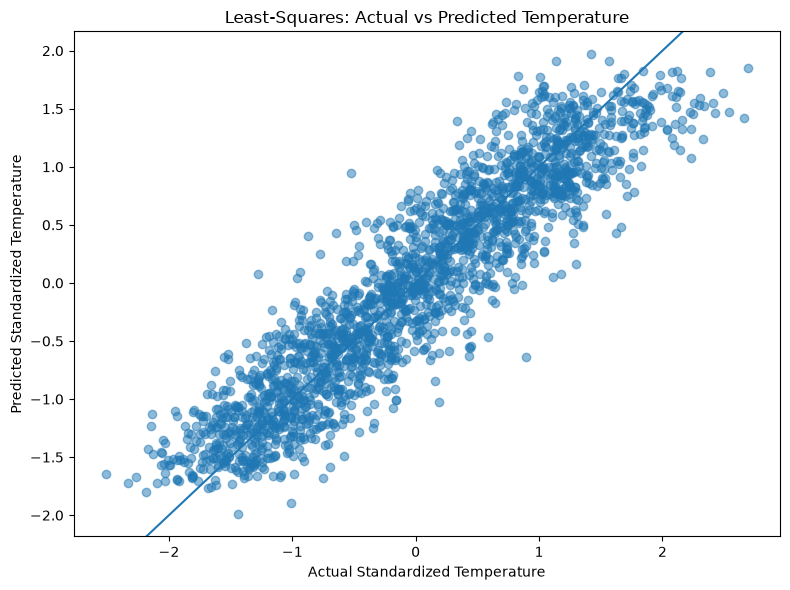

In [141]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_temperature,
    y_predicted,
    alpha=0.5
)

plt.xlabel("Actual Standardized Temperature")
plt.ylabel("Predicted Standardized Temperature")
plt.title("Least-Squares: Actual vs Predicted Temperature")

plt.axline((0, 0), slope=1)

plt.tight_layout()
plt.show()

## 6. Eigenvalues and Eigenvectors for Machine Operating Patterns

Eigenvalues and eigenvectors are used to identify the dominant patterns
present in the normal operating condition of the machine.

The covariance matrix of the normal machine observations is constructed.
Since the covariance matrix is symmetric, it can be decomposed using
eigenvalues and eigenvectors.

Large eigenvalues represent directions containing more variation in
the machine's normal operating behavior.

In [142]:
covariance_matrix = np.cov(
    X_normal_standardized,
    rowvar=False
)

print("Covariance matrix:")
print(covariance_matrix)

Covariance matrix:
[[0.8752476  0.48399948 0.86717396 0.50897742 0.09149848]
 [0.48399948 0.33860182 0.54878573 0.31920666 0.01562954]
 [0.86717396 0.54878573 1.00936858 0.56928136 0.04420795]
 [0.50897742 0.31920666 0.56928136 0.37777709 0.02532223]
 [0.09149848 0.01562954 0.04420795 0.02532223 0.94474437]]


In [143]:
eigenvalues, eigenvectors = np.linalg.eigh(
    covariance_matrix
)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[0.0307283  0.04335741 0.07967053 0.94095611 2.45102711]

Eigenvectors:
[[ 2.10304666e-02 -5.26660999e-04  8.14885867e-01 -4.82796987e-03
  -5.79219438e-01]
 [ 8.64911643e-01 -2.25082500e-01 -2.73233364e-01  4.34613823e-02
  -3.53157692e-01]
 [-5.01408045e-01 -3.96166924e-01 -4.35586194e-01  5.95860541e-02
  -6.31154427e-01]
 [-4.42797344e-03  8.90161071e-01 -2.62557973e-01  3.56907256e-02
  -3.70652323e-01]
 [ 7.47899040e-03 -1.62085190e-03 -5.13082028e-02 -9.96626045e-01
  -6.36037157e-02]]


In [144]:
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("Eigenvalues in descending order:")
print(eigenvalues)

Eigenvalues in descending order:
[2.45102711 0.94095611 0.07967053 0.04335741 0.0307283 ]


In [145]:
explained_variance_ratio = (
    eigenvalues / eigenvalues.sum()
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

print("Explained variance ratio:")
print(explained_variance_ratio)

print("\nCumulative explained variance:")
print(cumulative_variance)

Explained variance ratio:
[0.69125979 0.26537655 0.02246937 0.01222803 0.00866626]

Cumulative explained variance:
[0.69125979 0.95663634 0.97910571 0.99133374 1.        ]


In [146]:
for i in range(len(eigenvalues)):
    print(
        "Eigenvector", i + 1,
        ":",
        round(explained_variance_ratio[i] * 100, 2),
        "% variance"
    )

Eigenvector 1 : 69.13 % variance
Eigenvector 2 : 26.54 % variance
Eigenvector 3 : 2.25 % variance
Eigenvector 4 : 1.22 % variance
Eigenvector 5 : 0.87 % variance


In [147]:
# Select the first 2 eigenvectors
k = 2

Q_normal = eigenvectors[:, :k]

print("Normal operating basis:")
print(Q_normal)

print("\nBasis shape:", Q_normal.shape)

Normal operating basis:
[[-0.57921944 -0.00482797]
 [-0.35315769  0.04346138]
 [-0.63115443  0.05958605]
 [-0.37065232  0.03569073]
 [-0.06360372 -0.99662604]]

Basis shape: (5, 2)


In [148]:
basis_check = Q_normal.T @ Q_normal

print("Basis orthogonality check:")
print(np.round(basis_check, 5))

Basis orthogonality check:
[[ 1. -0.]
 [-0.  1.]]


## 7. Projection-Based Anomaly Detection

The first two eigenvectors represent 95.66% of the normal
machine operating variation.

A new machine observation can be projected onto this
normal operating subspace.

If the observation is close to the normal subspace, the
machine is likely operating normally.

If it is far from the normal subspace, the large projection
residual indicates abnormal machine behavior.

The anomaly score is defined as the Euclidean norm of
the projection residual.

In [149]:
# Project all machine observations onto the normal subspace

X_projection = (
    X_standardized @ Q_normal
) @ Q_normal.T

print("Projected data shape:", X_projection.shape)

Projected data shape: (2101, 5)


In [150]:
residuals = X_standardized - X_projection

print("Residual matrix shape:", residuals.shape)

Residual matrix shape: (2101, 5)


In [151]:
anomaly_scores = np.linalg.norm(
    residuals,
    axis=1
)

print("First 10 anomaly scores:")
print(anomaly_scores[:10])

First 10 anomaly scores:
[1.86302579 1.49680039 0.17826184 1.85013936 0.80557209 0.46165898
 0.57840389 0.41273594 0.75897851 1.59341962]


In [152]:
normal_scores = anomaly_scores[
    df["Fault_Type"] == "Normal"
]

print("Number of normal scores:", len(normal_scores))

print("\nNormal machine anomaly scores:")
print(normal_scores[:10])

Number of normal scores: 400

Normal machine anomaly scores:
[1.14785149 1.30795997 1.11187179 1.13120004 1.66767077 1.25084957
 1.1990397  1.54460172 1.19877105 1.52335006]


In [153]:
threshold = np.percentile(
    normal_scores,
    95
)

print("Anomaly detection threshold:", threshold)

Anomaly detection threshold: 1.58377737341816


In [154]:
detected_status = np.where(
    anomaly_scores > threshold,
    "Anomaly",
    "Normal"
)

print("First 20 detected statuses:")
print(detected_status[:20])

First 20 detected statuses:
['Anomaly' 'Normal' 'Normal' 'Anomaly' 'Normal' 'Normal' 'Normal' 'Normal'
 'Normal' 'Anomaly' 'Normal' 'Normal' 'Normal' 'Normal' 'Normal' 'Anomaly'
 'Anomaly' 'Normal' 'Normal' 'Normal']


In [155]:
df["Anomaly_Score"] = anomaly_scores
df["Detected_Status"] = detected_status

print(df[
    ["Fault_Type", "Anomaly_Score", "Detected_Status"]
].head(20))

            Fault_Type  Anomaly_Score Detected_Status
0      Rotor_Unbalance       1.863026         Anomaly
1      Rotor_Unbalance       1.496800          Normal
2   Bearing_Inner_Race       0.178262          Normal
3   Bearing_Inner_Race       1.850139         Anomaly
4   Bearing_Inner_Race       0.805572          Normal
5   Bearing_Inner_Race       0.461659          Normal
6      Rotor_Unbalance       0.578404          Normal
7   Bearing_Outer_Race       0.412736          Normal
8   Bearing_Inner_Race       0.758979          Normal
9   Bearing_Inner_Race       1.593420         Anomaly
10  Bearing_Inner_Race       0.550311          Normal
11              Normal       1.147851          Normal
12  Bearing_Inner_Race       0.445982          Normal
13  Shaft_Misalignment       0.312534          Normal
14  Bearing_Inner_Race       1.396009          Normal
15  Bearing_Inner_Race       1.763408         Anomaly
16     Rotor_Unbalance       1.641749         Anomaly
17  Bearing_Inner_Race      

In [156]:
print("Detection results:")
print(df["Detected_Status"].value_counts())

Detection results:
Detected_Status
Normal     1950
Anomaly     151
Name: count, dtype: int64


In [157]:
print("Detection results by actual fault type:")
print(
    pd.crosstab(
        df["Fault_Type"],
        df["Detected_Status"]
    )
)

Detection results by actual fault type:
Detected_Status     Anomaly  Normal
Fault_Type                         
Bearing_Inner_Race       71     529
Bearing_Outer_Race        1     449
Normal                   20     380
Rotor_Unbalance          54     271
Shaft_Misalignment        5     320


## 8. Improved PCA-Based Anomaly Detection

The previous detector used the residual from the normal operating
subspace. However, some faults may occur along the dominant
eigenvector directions and therefore may not produce a large
projection residual.

To improve detection, the normal machine data is used to learn
the mean and standard deviation.

The detector then considers both:

1. Deviation outside the normal subspace
2. Unusual movement along the dominant eigenvector directions

This provides a more complete measure of machine abnormality.

In [158]:
normal_mean = X_normal.mean(axis=0)
normal_std = X_normal.std(axis=0)

X_normal_scaled = (
    X_normal - normal_mean
) / normal_std

X_all_scaled = (
    X - normal_mean
) / normal_std

print("Normal-based standardization completed.")
print("Normal data shape:", X_normal_scaled.shape)
print("All data shape:", X_all_scaled.shape)

Normal-based standardization completed.
Normal data shape: (400, 5)
All data shape: (2101, 5)


In [159]:
covariance_normal = np.cov(
    X_normal_scaled,
    rowvar=False
)

print("Normal-data covariance matrix:")
print(covariance_normal)

Normal-data covariance matrix:
[[1.00250627 0.89129585 0.92491744 0.88736509 0.1008738 ]
 [0.89129585 1.00250627 0.94106663 0.89473946 0.0277033 ]
 [0.92491744 0.94106663 1.00250627 0.92421148 0.04538427]
 [0.88736509 0.89473946 0.92421148 1.00250627 0.04249268]
 [0.1008738  0.0277033  0.04538427 0.04249268 1.00250627]]


In [160]:
eigenvalues_normal, eigenvectors_normal = np.linalg.eigh(
    covariance_normal
)

# Sort from largest to smallest
idx = np.argsort(eigenvalues_normal)[::-1]

eigenvalues_normal = eigenvalues_normal[idx]
eigenvectors_normal = eigenvectors_normal[:, idx]

print("Eigenvalues:")
print(eigenvalues_normal)

Eigenvalues:
[3.73890241 1.00177004 0.1132604  0.1078502  0.05074828]


In [161]:
explained_normal = (
    eigenvalues_normal /
    eigenvalues_normal.sum()
)

cumulative_normal = np.cumsum(
    explained_normal
)

for i in range(len(eigenvalues_normal)):
    print(
        "Eigenvector", i + 1,
        ":",
        round(explained_normal[i] * 100, 2),
        "%",
        "| Cumulative:",
        round(cumulative_normal[i] * 100, 2),
        "%"
    )

Eigenvector 1 : 74.59 % | Cumulative: 74.59 %
Eigenvector 2 : 19.99 % | Cumulative: 94.58 %
Eigenvector 3 : 2.26 % | Cumulative: 96.84 %
Eigenvector 4 : 2.15 % | Cumulative: 98.99 %
Eigenvector 5 : 1.01 % | Cumulative: 100.0 %


In [162]:
k_improved = 2

Q_improved = eigenvectors_normal[:, :k_improved]

print("Improved normal subspace basis:")
print(Q_improved)

print("\nBasis shape:", Q_improved.shape)

Improved normal subspace basis:
[[-0.49624319  0.03350364]
 [-0.49871435 -0.04924938]
 [-0.50741594 -0.03031364]
 [-0.49598253 -0.03232795]
 [-0.03946004  0.99724019]]

Basis shape: (5, 2)


In [163]:
basis_check_improved = Q_improved.T @ Q_improved

print("Orthonormality check:")
print(np.round(basis_check_improved, 5))

Orthonormality check:
[[ 1. -0.]
 [-0.  1.]]


In [164]:
X_improved_projection = (
    X_all_scaled @ Q_improved
) @ Q_improved.T

print("Improved projected data shape:",
      X_improved_projection.shape)

Improved projected data shape: (2101, 5)


In [165]:
improved_residuals = (
    X_all_scaled - X_improved_projection
)

print("Improved residual matrix shape:",
      improved_residuals.shape)

Improved residual matrix shape: (2101, 5)


In [166]:
improved_anomaly_scores = np.linalg.norm(
    improved_residuals,
    axis=1
)

print("First 10 improved anomaly scores:")
print(improved_anomaly_scores[:10])

First 10 improved anomaly scores:
[4.2077832  3.66973665 1.55657147 4.11131225 2.64932143 1.12926717
 1.24538991 1.51963455 2.59143908 3.75741067]


In [167]:
normal_improved_scores = improved_anomaly_scores[
    df["Fault_Type"] == "Normal"
]

print("Number of normal scores:",
      len(normal_improved_scores))

Number of normal scores: 400


In [168]:
improved_threshold = np.percentile(
    normal_improved_scores,
    95
)

print(
    "Improved anomaly detection threshold:",
    improved_threshold
)

Improved anomaly detection threshold: 0.8608048583872002


In [169]:
improved_status = np.where(
    improved_anomaly_scores > improved_threshold,
    "Anomaly",
    "Normal"
)

df["Improved_Anomaly_Score"] = improved_anomaly_scores
df["Improved_Status"] = improved_status

print("Improved detection results:")
print(df["Improved_Status"].value_counts())

Improved detection results:
Improved_Status
Anomaly    1662
Normal      439
Name: count, dtype: int64


In [170]:
print("Improved detection by actual fault type:")
print(
    pd.crosstab(
        df["Fault_Type"],
        df["Improved_Status"]
    )
)

Improved detection by actual fault type:
Improved_Status     Anomaly  Normal
Fault_Type                         
Bearing_Inner_Race      585      15
Bearing_Outer_Race      415      35
Normal                   20     380
Rotor_Unbalance         325       0
Shaft_Misalignment      316       9


## 9. Anomaly Score Visualization

The anomaly score measures the distance of a machine observation
from the learned normal operating subspace.

The 95th-percentile score of normal machines is used as the
anomaly detection threshold.

Observations above the threshold are classified as anomalous.

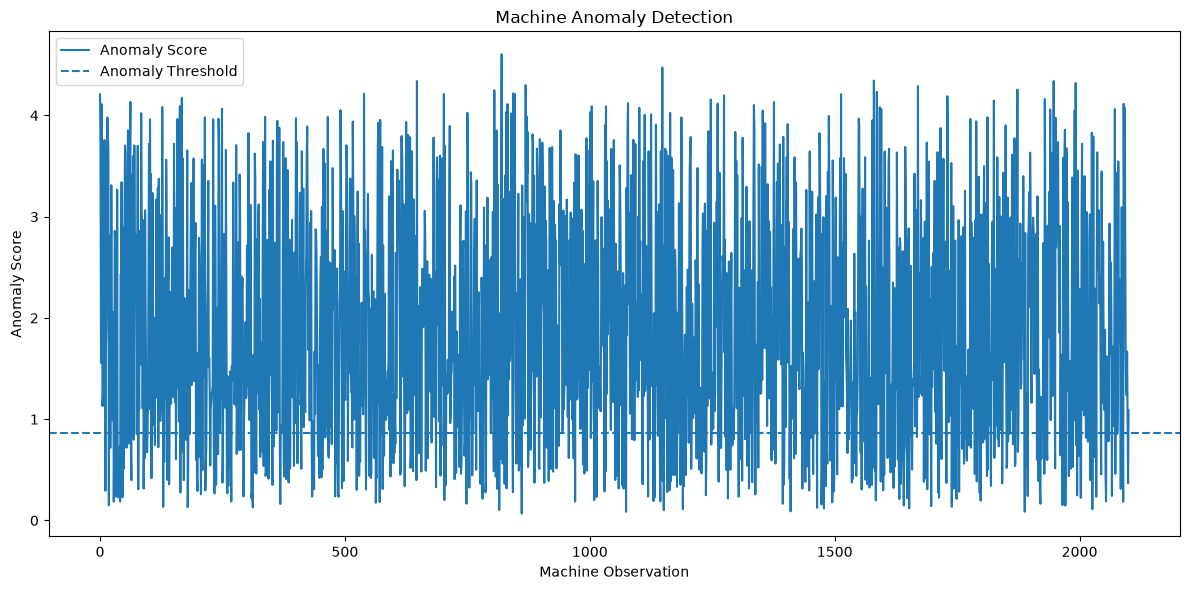

In [171]:
plt.figure(figsize=(12, 6))

plt.plot(
    improved_anomaly_scores,
    label="Anomaly Score"
)

plt.axhline(
    improved_threshold,
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Machine Observation")
plt.ylabel("Anomaly Score")
plt.title("Machine Anomaly Detection")

plt.legend()
plt.tight_layout()
plt.show()

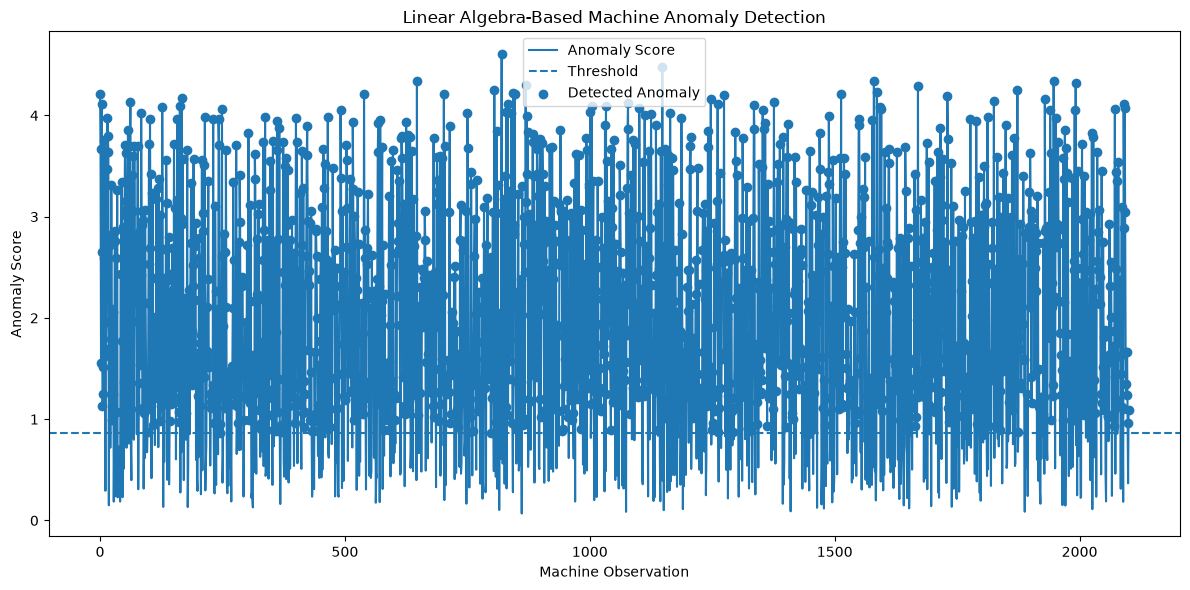

In [172]:
plt.figure(figsize=(12, 6))

plt.plot(
    improved_anomaly_scores,
    label="Anomaly Score"
)

plt.axhline(
    improved_threshold,
    linestyle="--",
    label="Threshold"
)

# Highlight detected anomalies
anomaly_indices = np.where(
    improved_anomaly_scores > improved_threshold
)[0]

plt.scatter(
    anomaly_indices,
    improved_anomaly_scores[anomaly_indices],
    label="Detected Anomaly"
)

plt.xlabel("Machine Observation")
plt.ylabel("Anomaly Score")
plt.title("Linear Algebra-Based Machine Anomaly Detection")

plt.legend()
plt.tight_layout()
plt.show()

In [173]:
detection_table = pd.crosstab(
    df["Fault_Type"],
    df["Improved_Status"]
)

fault_detection_rate = (
    detection_table["Anomaly"]
    / detection_table.sum(axis=1)
    * 100
)

print("Fault detection rates:")
print(fault_detection_rate)

Fault detection rates:
Fault_Type
Bearing_Inner_Race     97.500000
Bearing_Outer_Race     92.222222
Normal                  5.000000
Rotor_Unbalance       100.000000
Shaft_Misalignment     97.230769
dtype: float64


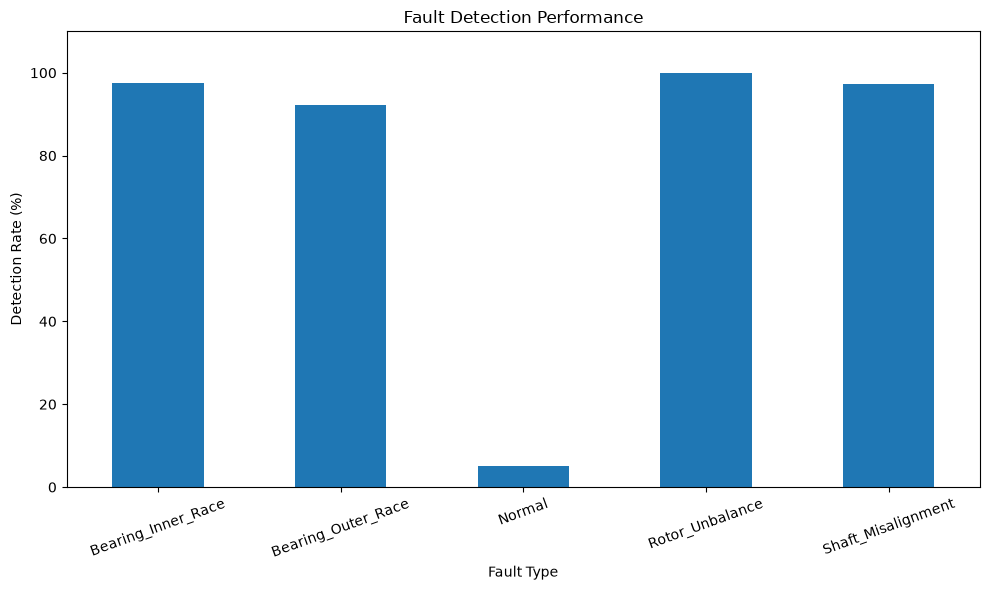

In [174]:
plt.figure(figsize=(10, 6))

fault_detection_rate.plot(kind="bar")

plt.ylabel("Detection Rate (%)")
plt.xlabel("Fault Type")
plt.title("Fault Detection Performance")

plt.xticks(rotation=20)
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

## 10. Sensor-Wise Fault Explanation

The anomaly score tells us whether a machine observation is abnormal,
but it does not explain which sensor contributes most to the anomaly.

The projection residual contains the deviation of each sensor from
the learned normal operating subspace.

The squared residual of each sensor is used to measure its contribution
to the overall anomaly.

In [175]:
sensor_contribution = improved_residuals ** 2

print("Sensor contribution matrix shape:")
print(sensor_contribution.shape)

Sensor contribution matrix shape:
(2101, 5)


In [176]:
sensor_names = [
    "Temperature",
    "Vibration",
    "Current",
    "Acoustic",
    "RPM"
]

dominant_sensor_index = np.argmax(
    sensor_contribution,
    axis=1
)

dominant_sensor = [
    sensor_names[i]
    for i in dominant_sensor_index
]

df["Dominant_Sensor"] = dominant_sensor

print(
    df[
        ["Fault_Type",
         "Improved_Anomaly_Score",
         "Improved_Status",
         "Dominant_Sensor"]
    ].head(20)
)

            Fault_Type  Improved_Anomaly_Score Improved_Status Dominant_Sensor
0      Rotor_Unbalance                4.207783         Anomaly       Vibration
1      Rotor_Unbalance                3.669737         Anomaly       Vibration
2   Bearing_Inner_Race                1.556571         Anomaly         Current
3   Bearing_Inner_Race                4.111312         Anomaly         Current
4   Bearing_Inner_Race                2.649321         Anomaly         Current
5   Bearing_Inner_Race                1.129267         Anomaly         Current
6      Rotor_Unbalance                1.245390         Anomaly       Vibration
7   Bearing_Outer_Race                1.519635         Anomaly         Current
8   Bearing_Inner_Race                2.591439         Anomaly         Current
9   Bearing_Inner_Race                3.757411         Anomaly         Current
10  Bearing_Inner_Race                1.628036         Anomaly        Acoustic
11              Normal                0.292994      

In [177]:
fault_examples = df[
    df["Fault_Type"] != "Normal"
][
    [
        "Fault_Type",
        "Improved_Anomaly_Score",
        "Improved_Status",
        "Dominant_Sensor"
    ]
].head(20)

print(fault_examples)

            Fault_Type  Improved_Anomaly_Score Improved_Status Dominant_Sensor
0      Rotor_Unbalance                4.207783         Anomaly       Vibration
1      Rotor_Unbalance                3.669737         Anomaly       Vibration
2   Bearing_Inner_Race                1.556571         Anomaly         Current
3   Bearing_Inner_Race                4.111312         Anomaly         Current
4   Bearing_Inner_Race                2.649321         Anomaly         Current
5   Bearing_Inner_Race                1.129267         Anomaly         Current
6      Rotor_Unbalance                1.245390         Anomaly       Vibration
7   Bearing_Outer_Race                1.519635         Anomaly         Current
8   Bearing_Inner_Race                2.591439         Anomaly         Current
9   Bearing_Inner_Race                3.757411         Anomaly         Current
10  Bearing_Inner_Race                1.628036         Anomaly        Acoustic
12  Bearing_Inner_Race                1.698134      

In [178]:
fault_sensor_summary = pd.crosstab(
    df["Fault_Type"],
    df["Dominant_Sensor"]
)

print("Dominant sensor by fault type:")
print(fault_sensor_summary)

Dominant sensor by fault type:
Dominant_Sensor     Acoustic  Current  Temperature  Vibration
Fault_Type                                                   
Bearing_Inner_Race       277      278           19         26
Bearing_Outer_Race       198      212           17         23
Normal                   123       60          117        100
Rotor_Unbalance            3       13            1        308
Shaft_Misalignment         5      189            1        130


## 11. Machine Health Score and Maintenance Recommendation

The anomaly score measures how far a machine observation deviates
from the learned normal operating subspace.

To make the result easier for an operator to understand, the
anomaly score is converted into a machine health score.

A higher health score indicates healthier machine operation.

In [179]:
health_score = (
    100 * (1 - improved_anomaly_scores / improved_threshold)
)

# Keep the score between 0 and 100
health_score = np.clip(
    health_score,
    0,
    100
)

df["Health_Score"] = health_score

print(df[
    [
        "Fault_Type",
        "Improved_Anomaly_Score",
        "Health_Score",
        "Improved_Status"
    ]
].head(20))

            Fault_Type  Improved_Anomaly_Score  Health_Score Improved_Status
0      Rotor_Unbalance                4.207783      0.000000         Anomaly
1      Rotor_Unbalance                3.669737      0.000000         Anomaly
2   Bearing_Inner_Race                1.556571      0.000000         Anomaly
3   Bearing_Inner_Race                4.111312      0.000000         Anomaly
4   Bearing_Inner_Race                2.649321      0.000000         Anomaly
5   Bearing_Inner_Race                1.129267      0.000000         Anomaly
6      Rotor_Unbalance                1.245390      0.000000         Anomaly
7   Bearing_Outer_Race                1.519635      0.000000         Anomaly
8   Bearing_Inner_Race                2.591439      0.000000         Anomaly
9   Bearing_Inner_Race                3.757411      0.000000         Anomaly
10  Bearing_Inner_Race                1.628036      0.000000         Anomaly
11              Normal                0.292994     65.962841          Normal

In [180]:
health_score = (
    100
    - 50 * (
        improved_anomaly_scores
        / improved_threshold
    )
)

health_score = np.clip(
    health_score,
    0,
    100
)

df["Health_Score"] = health_score

print(df[
    [
        "Fault_Type",
        "Improved_Anomaly_Score",
        "Health_Score",
        "Improved_Status"
    ]
].head(20))

            Fault_Type  Improved_Anomaly_Score  Health_Score Improved_Status
0      Rotor_Unbalance                4.207783      0.000000         Anomaly
1      Rotor_Unbalance                3.669737      0.000000         Anomaly
2   Bearing_Inner_Race                1.556571      9.586275         Anomaly
3   Bearing_Inner_Race                4.111312      0.000000         Anomaly
4   Bearing_Inner_Race                2.649321      0.000000         Anomaly
5   Bearing_Inner_Race                1.129267     34.406320         Anomaly
6      Rotor_Unbalance                1.245390     27.661311         Anomaly
7   Bearing_Outer_Race                1.519635     11.731763         Anomaly
8   Bearing_Inner_Race                2.591439      0.000000         Anomaly
9   Bearing_Inner_Race                3.757411      0.000000         Anomaly
10  Bearing_Inner_Race                1.628036      5.435238         Anomaly
11              Normal                0.292994     82.981420          Normal

In [181]:
maintenance_status = []

for score in df["Improved_Anomaly_Score"]:
    if score <= improved_threshold:
        maintenance_status.append("Normal Operation")
    elif score <= improved_threshold * 1.5:
        maintenance_status.append("Monitor Machine")
    else:
        maintenance_status.append("Maintenance Recommended")

df["Maintenance_Status"] = maintenance_status

print("Maintenance_Status column created successfully!")

Maintenance_Status column created successfully!


In [182]:
# Final Machine Health Report

# Select the first detected faulty/anomalous machine
demo_index = df.index[
    (df["Fault_Type"] != "Normal") &
    (df["Improved_Status"] == "Anomaly")
][0]

machine = df.loc[demo_index]

print("=" * 50)
print("        MACHINE HEALTH REPORT")
print("=" * 50)

print("Sample ID:", machine["Sample_ID"])
print("Anomaly Score:", round(machine["Improved_Anomaly_Score"], 3))
print("Threshold:", round(improved_threshold, 3))
print("Status:", machine["Improved_Status"])
print("Dominant Sensor:", machine["Dominant_Sensor"])
print("Health Score:", round(machine["Health_Score"], 2))
print("Maintenance Status:", machine["Maintenance_Status"])

print("=" * 50)

        MACHINE HEALTH REPORT
Sample ID: 1
Anomaly Score: 4.208
Threshold: 0.861
Status: Anomaly
Dominant Sensor: Vibration
Health Score: 0.0
Maintenance Status: Maintenance Recommended


In [183]:
# Diagonalization of the covariance matrix

Lambda = np.diag(eigenvalues_normal)

reconstructed_covariance = (
    eigenvectors_normal
    @ Lambda
    @ eigenvectors_normal.T
)

reconstruction_error = np.max(
    np.abs(covariance_normal - reconstructed_covariance)
)

print("Original covariance matrix:")
print(covariance_normal)

print("\nReconstructed covariance matrix:")
print(reconstructed_covariance)

print("\nMaximum reconstruction error:",
      reconstruction_error)

Original covariance matrix:
[[1.00250627 0.89129585 0.92491744 0.88736509 0.1008738 ]
 [0.89129585 1.00250627 0.94106663 0.89473946 0.0277033 ]
 [0.92491744 0.94106663 1.00250627 0.92421148 0.04538427]
 [0.88736509 0.89473946 0.92421148 1.00250627 0.04249268]
 [0.1008738  0.0277033  0.04538427 0.04249268 1.00250627]]

Reconstructed covariance matrix:
[[1.00250627 0.89129585 0.92491744 0.88736509 0.1008738 ]
 [0.89129585 1.00250627 0.94106663 0.89473946 0.0277033 ]
 [0.92491744 0.94106663 1.00250627 0.92421148 0.04538427]
 [0.88736509 0.89473946 0.92421148 1.00250627 0.04249268]
 [0.1008738  0.0277033  0.04538427 0.04249268 1.00250627]]

Maximum reconstruction error: 2.886579864025407e-15


In [184]:
# LU Decomposition of the covariance matrix

from scipy.linalg import lu

P, L, U = lu(covariance_normal)

print("L matrix:")
print(L)

print("\nU matrix:")
print(U)

print("\nPermutation matrix P:")
print(P)

# Verify A = P @ L @ U
reconstructed_LU = P @ L @ U

lu_error = np.max(
    np.abs(covariance_normal - reconstructed_LU)
)

print("\nMaximum LU reconstruction error:", lu_error)

L matrix:
[[ 1.          0.          0.          0.          0.        ]
 [ 0.88906761  1.          0.          0.          0.        ]
 [ 0.92260514  0.56526197  1.          0.          0.        ]
 [ 0.88514668  0.50366475  0.55715346  1.          0.        ]
 [ 0.10062161 -0.29502639 -0.15414802 -0.06169141  1.        ]]

U matrix:
[[ 1.00250627  0.89129585  0.92491744  0.88736509  0.1008738 ]
 [ 0.          0.210084    0.11875249  0.1058119  -0.06198032]
 [ 0.          0.          0.08204641  0.04571244 -0.01264729]
 [ 0.          0.          0.          0.13829543 -0.00853164]
 [ 0.          0.          0.          0.          0.97159447]]

Permutation matrix P:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]

Maximum LU reconstruction error: 6.938893903907228e-18


In [185]:
# Rank-Nullity Theorem

number_of_features = len(features)

nullity = number_of_features - rank

print("Number of features:", number_of_features)
print("Rank:", rank)
print("Nullity:", nullity)

print("\nRank + Nullity =", rank + nullity)

Number of features: 5
Rank: 5
Nullity: 0

Rank + Nullity = 5


In [186]:
# Rank-Nullity Theorem

number_of_features = len(features)

nullity = number_of_features - rank

print("Number of features:", number_of_features)
print("Rank:", rank)
print("Nullity:", nullity)

print("\nRank + Nullity =", rank + nullity)

Number of features: 5
Rank: 5
Nullity: 0

Rank + Nullity = 5


In [187]:
# Final Detection Results

results = pd.DataFrame({
    "Fault Type": df["Fault_Type"],
    "Anomaly Score": df["Improved_Anomaly_Score"],
    "Status": df["Improved_Status"],
    "Dominant Sensor": df["Dominant_Sensor"],
    "Health Score": df["Health_Score"],
    "Maintenance": df["Maintenance_Status"]
})

print(results.head(10))

           Fault Type  Anomaly Score   Status Dominant Sensor  Health Score  \
0     Rotor_Unbalance       4.207783  Anomaly       Vibration      0.000000   
1     Rotor_Unbalance       3.669737  Anomaly       Vibration      0.000000   
2  Bearing_Inner_Race       1.556571  Anomaly         Current      9.586275   
3  Bearing_Inner_Race       4.111312  Anomaly         Current      0.000000   
4  Bearing_Inner_Race       2.649321  Anomaly         Current      0.000000   
5  Bearing_Inner_Race       1.129267  Anomaly         Current     34.406320   
6     Rotor_Unbalance       1.245390  Anomaly       Vibration     27.661311   
7  Bearing_Outer_Race       1.519635  Anomaly         Current     11.731763   
8  Bearing_Inner_Race       2.591439  Anomaly         Current      0.000000   
9  Bearing_Inner_Race       3.757411  Anomaly         Current      0.000000   

               Maintenance  
0  Maintenance Recommended  
1  Maintenance Recommended  
2  Maintenance Recommended  
3  Maintenance

In [188]:
# Fault Detection Performance

performance = pd.crosstab(
    df["Fault_Type"],
    df["Improved_Status"]
)

performance["Detection_Rate_%"] = (
    performance["Anomaly"] /
    performance.sum(axis=1)
) * 100

print(performance)

Improved_Status     Anomaly  Normal  Detection_Rate_%
Fault_Type                                           
Bearing_Inner_Race      585      15         97.500000
Bearing_Outer_Race      415      35         92.222222
Normal                   20     380          5.000000
Rotor_Unbalance         325       0        100.000000
Shaft_Misalignment      316       9         97.230769


In [189]:
# Interactive Machine Checker

machine_id = int(input("Enter Machine ID: "))

machine_rows = df[df["Sample_ID"] == machine_id]

if len(machine_rows) == 0:
    print("Machine ID not found.")
else:
    machine = machine_rows.iloc[0]

    print("\nMachine found!")
    print("Machine ID:", machine["Sample_ID"])
    print("Temperature:", machine["Temperature_C"], "°C")
    print("Vibration:", machine["Vibration_RMS_g"], "g")
    print("Current:", machine["Current_RMS_A"], "A")
    print("Acoustic:", machine["Acoustic_RMS_Pa"], "Pa")
    print("RPM:", machine["RPM"])


Machine found!
Machine ID: 1
Temperature: 43.785 °C
Vibration: 0.06343 g
Current: 2.3502 A
Acoustic: 0.018757 Pa
RPM: 3003.09


In [190]:
# Complete Machine Analysis

machine_id = int(input("Enter Machine ID: "))

machine_rows = df[df["Sample_ID"] == machine_id]

if len(machine_rows) == 0:
    print("Machine ID not found.")

else:
    machine = machine_rows.iloc[0]

    # Get the five sensor values
    machine_values = machine[features].to_numpy(dtype=float)

    # Standardize using normal-machine baseline
    machine_scaled = (machine_values - normal_mean) / normal_std

    # Project onto normal operating subspace
    machine_projection = (
        machine_scaled @ Q_improved
    ) @ Q_improved.T

    # Calculate residual
    machine_residual = machine_scaled - machine_projection

    # Calculate anomaly score
    machine_anomaly_score = np.linalg.norm(machine_residual)

    # Determine status
    if machine_anomaly_score > improved_threshold:
        machine_status = "ANOMALY"
    else:
        machine_status = "NORMAL"

    # Health score
    machine_health_score = 100 - 50 * (
        machine_anomaly_score / improved_threshold
    )

    machine_health_score = np.clip(
        machine_health_score, 0, 100
    )

    # Find dominant sensor
    sensor_contributions = machine_residual ** 2
    dominant_index = np.argmax(sensor_contributions)
    dominant_sensor = sensor_names[dominant_index]

    # Maintenance recommendation
    if machine_anomaly_score <= improved_threshold:
        maintenance = "Normal Operation"
    elif machine_anomaly_score <= improved_threshold * 1.5:
        maintenance = "Monitor Machine"
    else:
        maintenance = "Maintenance Recommended"

    # Display report
    print("\n" + "=" * 55)
    print("             MACHINE HEALTH REPORT")
    print("=" * 55)

    print("\nMachine ID:", machine["Sample_ID"])

    print("\n--- Sensor Readings ---")
    print("Temperature :", machine["Temperature_C"], "°C")
    print("Vibration   :", machine["Vibration_RMS_g"], "g")
    print("Current     :", machine["Current_RMS_A"], "A")
    print("Acoustic    :", machine["Acoustic_RMS_Pa"], "Pa")
    print("RPM         :", machine["RPM"])

    print("\n--- Mathematical Analysis ---")
    print("Anomaly Score :", round(machine_anomaly_score, 3))
    print("Threshold     :", round(improved_threshold, 3))
    print("Status        :", machine_status)
    print("Health Score  :", round(machine_health_score, 2), "/ 100")
    print("Dominant Sensor:", dominant_sensor)

    print("\n--- Maintenance Recommendation ---")
    print(maintenance)

    print("=" * 55)


             MACHINE HEALTH REPORT

Machine ID: 1

--- Sensor Readings ---
Temperature : 43.785 °C
Vibration   : 0.06343 g
Current     : 2.3502 A
Acoustic    : 0.018757 Pa
RPM         : 3003.09

--- Mathematical Analysis ---
Anomaly Score : 4.208
Threshold     : 0.861
Status        : ANOMALY
Health Score  : 0.0 / 100
Dominant Sensor: Vibration

--- Maintenance Recommendation ---
Maintenance Recommended


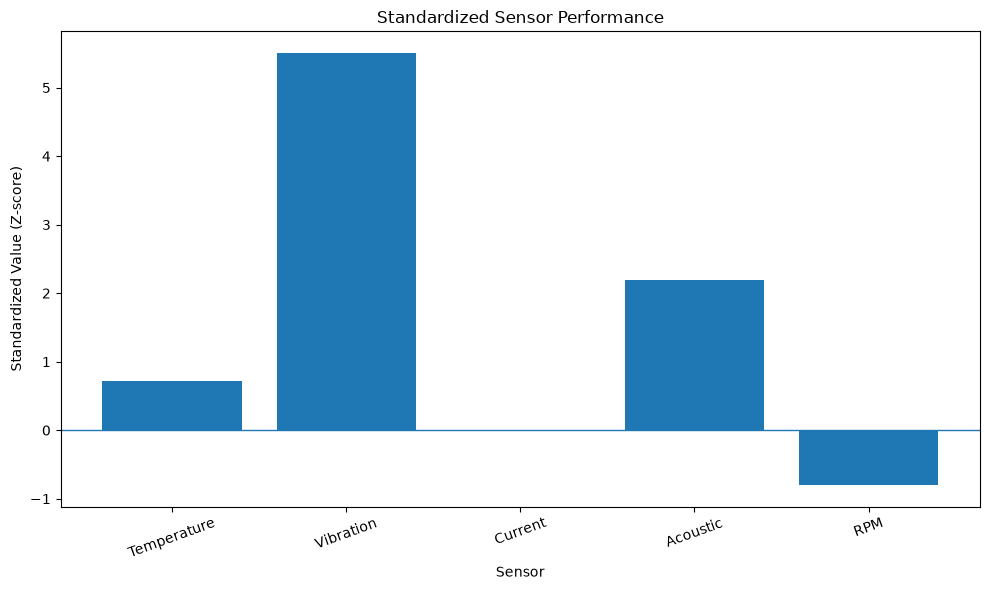

In [191]:
# Standardized Machine Sensor Performance

if len(machine_rows) != 0:

    standardized_values = machine_scaled

    sensor_labels = [
        "Temperature",
        "Vibration",
        "Current",
        "Acoustic",
        "RPM"
    ]

    plt.figure(figsize=(10, 6))

    plt.bar(sensor_labels, standardized_values)

    plt.axhline(0, linewidth=1)

    plt.title("Standardized Sensor Performance")
    plt.xlabel("Sensor")
    plt.ylabel("Standardized Value (Z-score)")

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

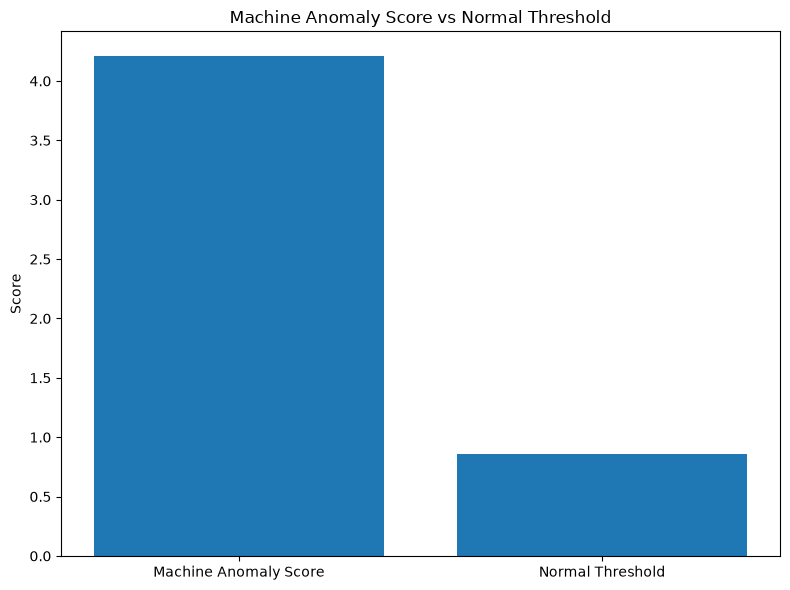

In [192]:
# Anomaly Score vs Normal Threshold

plt.figure(figsize=(8, 6))

plt.bar(
    ["Machine Anomaly Score", "Normal Threshold"],
    [machine_anomaly_score, improved_threshold]
)

plt.ylabel("Score")
plt.title("Machine Anomaly Score vs Normal Threshold")

plt.tight_layout()
plt.show()

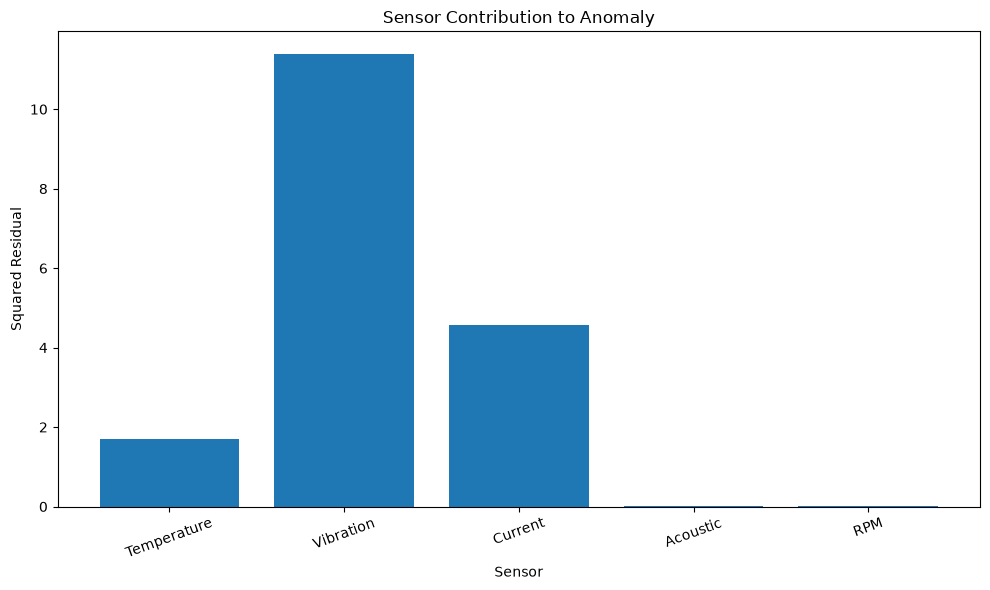

In [193]:
# Sensor Contribution to Anomaly

contribution_values = machine_residual ** 2

sensor_labels = [
    "Temperature",
    "Vibration",
    "Current",
    "Acoustic",
    "RPM"
]

plt.figure(figsize=(10, 6))

plt.bar(sensor_labels, contribution_values)

plt.title("Sensor Contribution to Anomaly")
plt.xlabel("Sensor")
plt.ylabel("Squared Residual")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [194]:
def check_machine(machine_id):

    machine_rows = df[df["Sample_ID"] == machine_id]

    if len(machine_rows) == 0:
        print("Machine ID not found.")
        return

    machine = machine_rows.iloc[0]

    # Sensor values
    machine_values = machine[features].to_numpy(dtype=float)

    # Standardization
    machine_scaled = (machine_values - normal_mean) / normal_std

    # Projection onto normal operating subspace
    machine_projection = (
        machine_scaled @ Q_improved
    ) @ Q_improved.T

    # Residual
    machine_residual = machine_scaled - machine_projection

    # Anomaly score
    anomaly_score = np.linalg.norm(machine_residual)

    # Status
    if anomaly_score > improved_threshold:
        status = "ANOMALY"
    else:
        status = "NORMAL"

    # Health score
    health_score = 100 - 50 * (
        anomaly_score / improved_threshold
    )

    health_score = np.clip(health_score, 0, 100)

    # Sensor contribution
    contributions = machine_residual ** 2

    dominant_index = np.argmax(contributions)
    dominant_sensor = sensor_names[dominant_index]

    # Maintenance recommendation
    if anomaly_score <= improved_threshold:
        maintenance = "Normal Operation"
    elif anomaly_score <= improved_threshold * 1.5:
        maintenance = "Monitor Machine"
    else:
        maintenance = "Maintenance Recommended"

    # -----------------------------
    # REPORT
    # -----------------------------

    print("\n" + "=" * 55)
    print("              MACHINE HEALTH REPORT")
    print("=" * 55)

    print("\nMachine ID:", machine["Sample_ID"])

    print("\n--- Sensor Readings ---")
    print("Temperature :", machine["Temperature_C"], "°C")
    print("Vibration   :", machine["Vibration_RMS_g"], "g")
    print("Current     :", machine["Current_RMS_A"], "A")
    print("Acoustic    :", machine["Acoustic_RMS_Pa"], "Pa")
    print("RPM         :", machine["RPM"])

    print("\n--- Analysis ---")
    print("Anomaly Score :", round(anomaly_score, 3))
    print("Threshold     :", round(improved_threshold, 3))
    print("Status        :", status)
    print("Health Score  :", round(health_score, 2), "/ 100")
    print("Dominant Sensor:", dominant_sensor)

    print("\n--- Recommendation ---")
    print(maintenance)

    print("=" * 55)

    # -----------------------------
    # GRAPH 1: STANDARDIZED SENSORS
    # -----------------------------

    plt.figure(figsize=(9, 5))

    plt.bar(sensor_names, machine_scaled)

    plt.axhline(0, linewidth=1)

    plt.title("Standardized Sensor Performance")
    plt.ylabel("Standardized Value (Z-score)")
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

    # -----------------------------
    # GRAPH 2: ANOMALY VS THRESHOLD
    # -----------------------------

    plt.figure(figsize=(7, 5))

    plt.bar(
        ["Machine Score", "Normal Threshold"],
        [anomaly_score, improved_threshold]
    )

    plt.ylabel("Score")
    plt.title("Anomaly Score vs Normal Threshold")

    plt.tight_layout()
    plt.show()

    # -----------------------------
    # GRAPH 3: SENSOR CONTRIBUTION
    # -----------------------------

    plt.figure(figsize=(9, 5))

    plt.bar(sensor_names, contributions)

    plt.title("Sensor Contribution to Anomaly")
    plt.ylabel("Squared Residual")
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

In [195]:
def check_machine(machine_id):

    machine_rows = df[df["Sample_ID"] == machine_id]

    if len(machine_rows) == 0:
        print("Machine ID not found.")
        return

    machine = machine_rows.iloc[0]

    # Get sensor values
    machine_values = machine[features].to_numpy(dtype=float)

    # Standardize using normal-machine statistics
    machine_scaled = (machine_values - normal_mean) / normal_std

    # Project onto normal operating subspace
    machine_projection = (machine_scaled @ Q_improved) @ Q_improved.T

    # Calculate residual
    machine_residual = machine_scaled - machine_projection

    # Calculate anomaly score
    anomaly_score = np.linalg.norm(machine_residual)

    # Determine status
    if anomaly_score > improved_threshold:
        status = "ANOMALY"
    else:
        status = "NORMAL"

    # Health score
    health_score = 100 - 50 * (anomaly_score / improved_threshold)
    health_score = np.clip(health_score, 0, 100)

    # Sensor contribution
    contributions = machine_residual ** 2
    dominant_index = np.argmax(contributions)
    dominant_sensor = sensor_names[dominant_index]

    # Maintenance recommendation
    if anomaly_score <= improved_threshold:
        maintenance = "Normal Operation"
    elif anomaly_score <= improved_threshold * 1.5:
        maintenance = "Monitor Machine"
    else:
        maintenance = "Maintenance Recommended"

    # Print report
    print("=" * 55)
    print("              MACHINE HEALTH REPORT")
    print("=" * 55)

    print("Machine ID:", machine_id)

    print("\n--- Sensor Readings ---")
    print(f"Temperature : {machine['Temperature_C']:.3f} °C")
    print(f"Vibration   : {machine['Vibration_RMS_g']:.5f} g")
    print(f"Current     : {machine['Current_RMS_A']:.4f} A")
    print(f"Acoustic    : {machine['Acoustic_RMS_Pa']:.6f} Pa")
    print(f"RPM         : {machine['RPM']:.2f}")

    print("\n--- Analysis ---")
    print(f"Anomaly Score : {anomaly_score:.3f}")
    print(f"Threshold     : {improved_threshold:.3f}")
    print(f"Status        : {status}")
    print(f"Health Score  : {health_score:.2f} / 100")
    print(f"Dominant Sensor: {dominant_sensor}")

    print("\n--- Recommendation ---")
    print(maintenance)

    print("=" * 55)

In [196]:
machine_id = int(input("Enter Machine ID: "))
check_machine(machine_id)

              MACHINE HEALTH REPORT
Machine ID: 1

--- Sensor Readings ---
Temperature : 43.785 °C
Vibration   : 0.06343 g
Current     : 2.3502 A
Acoustic    : 0.018757 Pa
RPM         : 3003.09

--- Analysis ---
Anomaly Score : 4.208
Threshold     : 0.861
Status        : ANOMALY
Health Score  : 0.00 / 100
Dominant Sensor: Vibration

--- Recommendation ---
Maintenance Recommended


In [ ]:
import pandas as pd
import numpy as np

def check_machine():
    # Load the latest CSV whenever the checker runs
    df = pd.read_csv("machine_fault_project_dataset_5_parameters_random_ids.csv")

    machine_id = int(input("Enter Machine ID: "))

    machine_rows = df[df["Sample_ID"] == machine_id]

    if machine_rows.empty:
        print("Machine ID not found in the CSV.")
        print("Check that you saved the CSV and entered the correct ID.")
        return

    machine = machine_rows.iloc[0]

    # Get the five sensor readings
    sensor_values = machine[features].to_numpy(dtype=float)

    # Use the normal baseline already calculated by your model
    scaled_values = (sensor_values - normal_mean) / normal_std

    # Project onto the learned normal operating subspace
    projected_values = (scaled_values @ Q_improved) @ Q_improved.T
    residual = scaled_values - projected_values

    # Calculate anomaly score
    anomaly_score = np.linalg.norm(residual)
    status = "ANOMALY" if anomaly_score > improved_threshold else "NORMAL"

    # Project-defined health score
    health_score = 100 / (1 + anomaly_score / improved_threshold)

    # Identify the sensor contributing most to the residual
    contributions = residual ** 2
    sensor_names = [
        "Temperature", "Vibration", "Current", "Acoustic", "RPM"
    ]
    dominant_sensor = sensor_names[np.argmax(contributions)]

    # Prototype maintenance rule
    if anomaly_score <= improved_threshold:
        recommendation = "Normal Operation"
    elif anomaly_score <= improved_threshold * 1.5:
        recommendation = "Monitor Machine"
    else:
        recommendation = "Maintenance Recommended"

    # Display report
    print("\n" + "=" * 50)
    print("             MACHINE HEALTH REPORT")
    print("=" * 50)
    print("Machine ID:", machine["Sample_ID"])
    print("Dataset Fault Label:", machine["Fault_Type"])
    print("\n--- Sensor Readings ---")
    print(f"Temperature : {machine['Temperature_C']} °C")
    print(f"Vibration   : {machine['Vibration_RMS_g']} g")
    print(f"Current     : {machine['Current_RMS_A']} A")
    print(f"Acoustic    : {machine['Acoustic_RMS_Pa']} Pa")
    print(f"RPM         : {machine['RPM']}")

    print("\n--- Model Analysis ---")
    print(f"Anomaly Score : {anomaly_score:.3f}")
    print(f"Threshold     : {improved_threshold:.3f}")
    print("Model Status  :", status)
    print(f"Health Score  : {health_score:.2f} / 100")
    print("Dominant Sensor:", dominant_sensor)

    print("\n--- Recommendation ---")
    print(recommendation)
    print("=" * 50)

# Run the checker
check_machine()


             MACHINE HEALTH REPORT
Machine ID: 1
Dataset Fault Label: Rotor_Unbalance

--- Sensor Readings ---
Temperature : 43.785 °C
Vibration   : 0.06343 g
Current     : 2.3502 A
Acoustic    : 0.018757 Pa
RPM         : 3003.09

--- Model Analysis ---
Anomaly Score : 4.208
Threshold     : 0.861
Model Status  : ANOMALY
Health Score  : 0.00 / 100
Dominant Sensor: Vibration

--- Recommendation ---
Maintenance Recommended
